In [1]:
import pandas as pd
from pathlib import Path

# Folder containing your CSV files
folder_path = Path(
    # r"C:\Users\Hitesh Chaudhary\OneDrive\Desktop\Hitesh Practice\pm4py Tables"
    r"C:\Users\Hitesh Chaudhary\OneDrive\Desktop\Hitesh Practice\New DATA set for PM4PY\p2p_process_mining_data"
)

# Dictionary to store all DataFrames
dfs = {}

# Read every CSV file in the folder
for file in folder_path.glob("*.csv"):
    table_name = file.stem
    dfs[table_name] = pd.read_csv(file, dtype=str)

print(f"Loaded {len(dfs)} CSV files successfully!")

# Display all table names
print(list(dfs.keys()))

Loaded 16 CSV files successfully!
['CDHDR_change_header', 'CDPOS_change_items', 'EBAN_purchase_requisitions', 'EKKO_po_header', 'EKPO_po_items', 'EVENT_LOG_derived', 'LFA1_vendors', 'MARA_materials', 'MKPF_goods_receipt_header', 'MSEG_goods_receipt_items', 'PAYMENTS', 'RBKP_invoice_header', 'RELATIONSHIPS', 'RSEG_invoice_items', 'T001W_plants', 'USERS']


In [2]:
print("\nSample data from each table:")
# Display sample data from each DataFrame
for table_name, df in dfs.items():
    print(f"\nTable: {table_name}")
    print(df.head())


Sample data from each table:

Table: CDHDR_change_header
    change_id object_class   object_id changed_by           changed_at  \
0  9000000001    EINKBELEG  4500000003      BUY01  2026-05-20 09:38:14   
1  9000000002    EINKBELEG  4500000006      BUY02  2026-02-02 11:15:16   
2  9000000003    EINKBELEG  4500000010      BUY01  2026-04-01 16:02:17   
3  9000000004    EINKBELEG  4500000015      BUY02  2026-02-23 08:42:37   
4  9000000005    EINKBELEG  4500000015      BUY02  2026-02-24 17:58:22   

  transaction_code  
0            ME22N  
1            ME22N  
2            ME22N  
3            ME22N  
4            ME22N  

Table: CDPOS_change_items
    change_id object_class   object_id table_name        table_key field_name  \
0  9000000001    EINKBELEG  4500000003       EKPO  450000000300010      MENGE   
1  9000000002    EINKBELEG  4500000006       EKPO  450000000600010      MENGE   
2  9000000003    EINKBELEG  4500000010       EKKO       4500000010      ZTERM   
3  9000000004    EIN

In [3]:
print(dfs["EVENT_LOG_derived"].columns.tolist())
print(dfs["EVENT_LOG_derived"].head())

['event_id', 'case_id', 'activity', 'timestamp', 'resource', 'source_table', 'source_key', 'vendor_id', 'total_value']
  event_id     case_id                      activity            timestamp  \
0        1  4500000001   Create Purchase Requisition  2026-06-16 08:14:08   
1        2  4500000001  Approve Purchase Requisition  2026-06-17 13:16:00   
2        3  4500000001         Create Purchase Order  2026-06-19 08:38:29   
3        4  4500000001            Post Goods Receipt  2026-07-09 08:56:34   
4        5  4500000001               Receive Invoice  2026-07-13 15:51:38   

  resource source_table  source_key vendor_id total_value  
0    REQ07         EBAN  1000000001   V100018    25302.92  
1    APR02         EBAN  1000000001   V100018    25302.92  
2    BUY03         EKKO  4500000001   V100018    25302.92  
3     WH03         MKPF  5000000001   V100018    25302.92  
4    APC02         RBKP  5105600001   V100018    25302.92  


In [4]:
import pandas as pd
import pm4py

# 1. Take the event log table out of your dictionary
event_log_df = dfs["EVENT_LOG_derived"].copy()

# 2. Fix the data types
event_log_df["case_id"] = event_log_df["case_id"].astype(str)
event_log_df["timestamp"] = pd.to_datetime(event_log_df["timestamp"])

# 3. Convert to pm4py's standard column names
event_log_df = pm4py.format_dataframe(
    event_log_df,
    case_id="case_id",
    activity_key="activity",
    timestamp_key="timestamp",
)
event_log_df = event_log_df.sort_values(["case:concept:name", "time:timestamp"])

print(event_log_df.columns.tolist())
print(event_log_df["case:concept:name"].nunique(), "cases")   # should be 600



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




['event_id', 'case_id', 'activity', 'timestamp', 'resource', 'source_table', 'source_key', 'vendor_id', 'total_value', 'case:concept:name', 'concept:name', 'time:timestamp', '@@index', '@@case_index']
600 cases


In [5]:
import os, shutil, sys
from pathlib import Path

dot_path = Path(r"C:\Program Files\Graphviz\bin\dot.exe")
print("python:", sys.executable)
print("dot.exe exists:", dot_path.exists())

# 1) add to PATH
os.environ["PATH"] = str(dot_path.parent) + os.pathsep + os.environ["PATH"]
print("which dot:", shutil.which("dot"))

# 2) force the graphviz package to use the full path
import graphviz.backend.dot_command as dc
dc.DOT_BINARY = dot_path
print("DOT_BINARY:", dc.DOT_BINARY)


python: c:\Users\Hitesh Chaudhary\OneDrive\Desktop\pm4pytest\venv\Scripts\python.exe
dot.exe exists: True
which dot: C:\Program Files\Graphviz\bin\dot.EXE
DOT_BINARY: C:\Program Files\Graphviz\bin\dot.exe


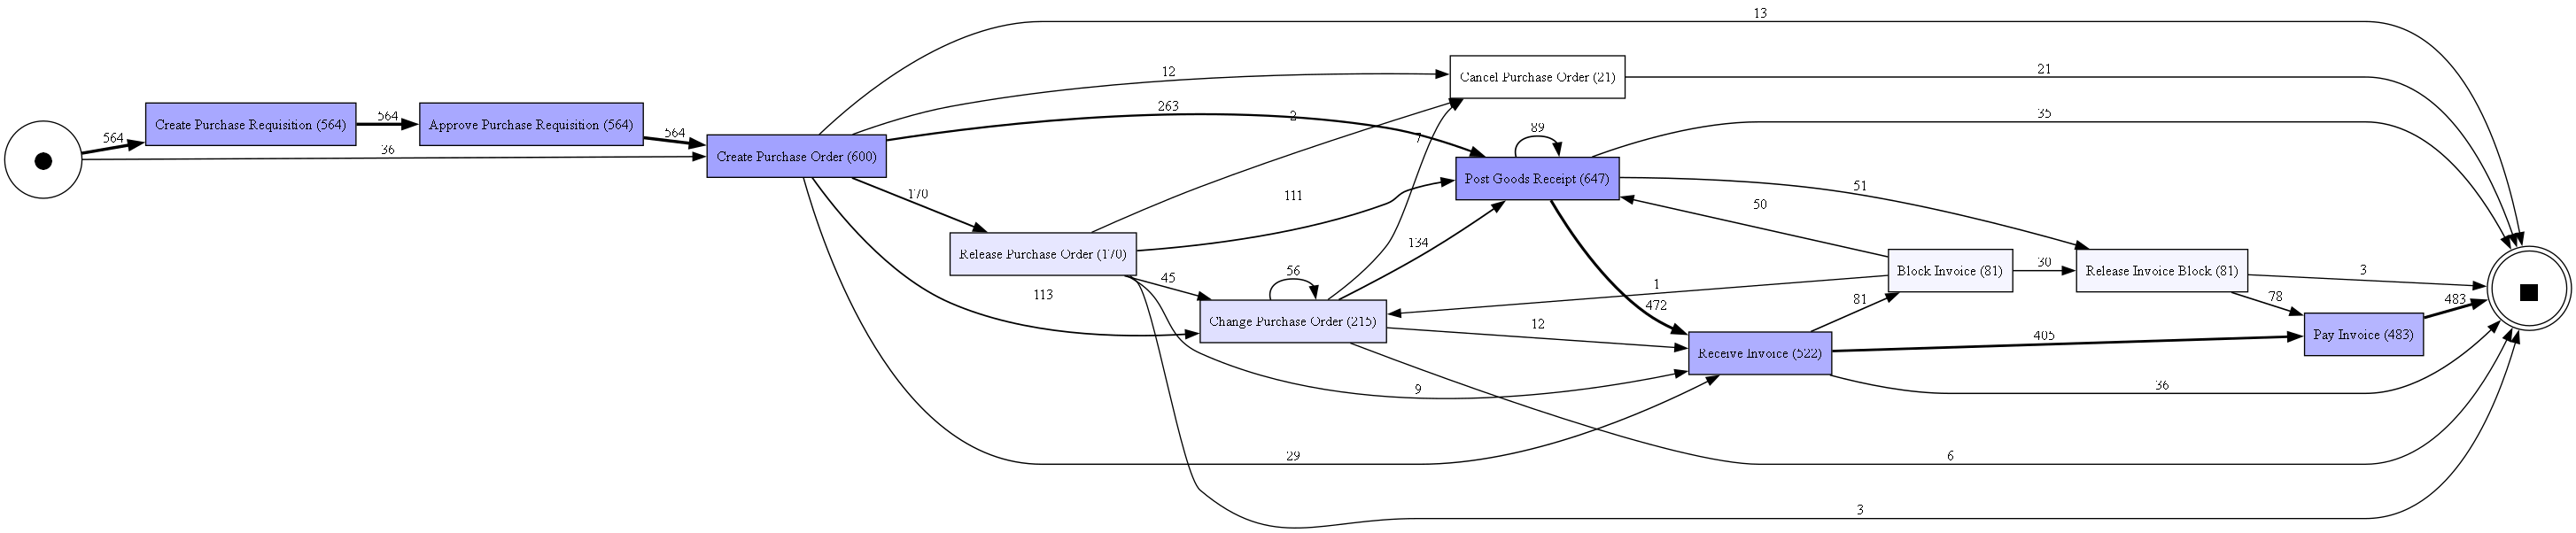

In [6]:
dfg, start_acts, end_acts = pm4py.discover_dfg(event_log_df)
pm4py.view_dfg(dfg, start_acts, end_acts)

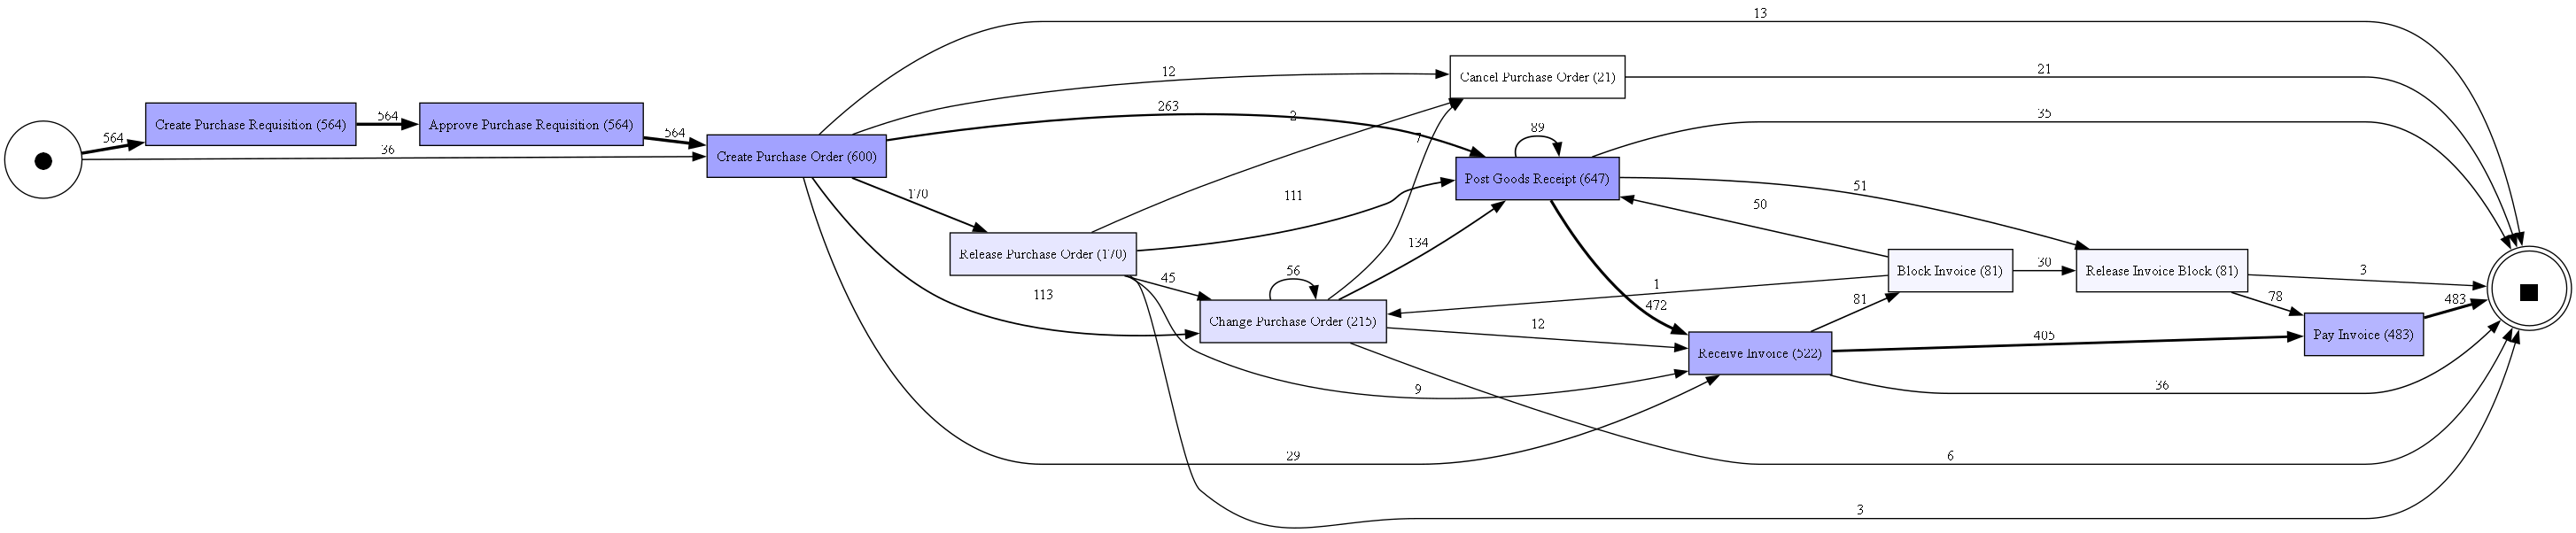

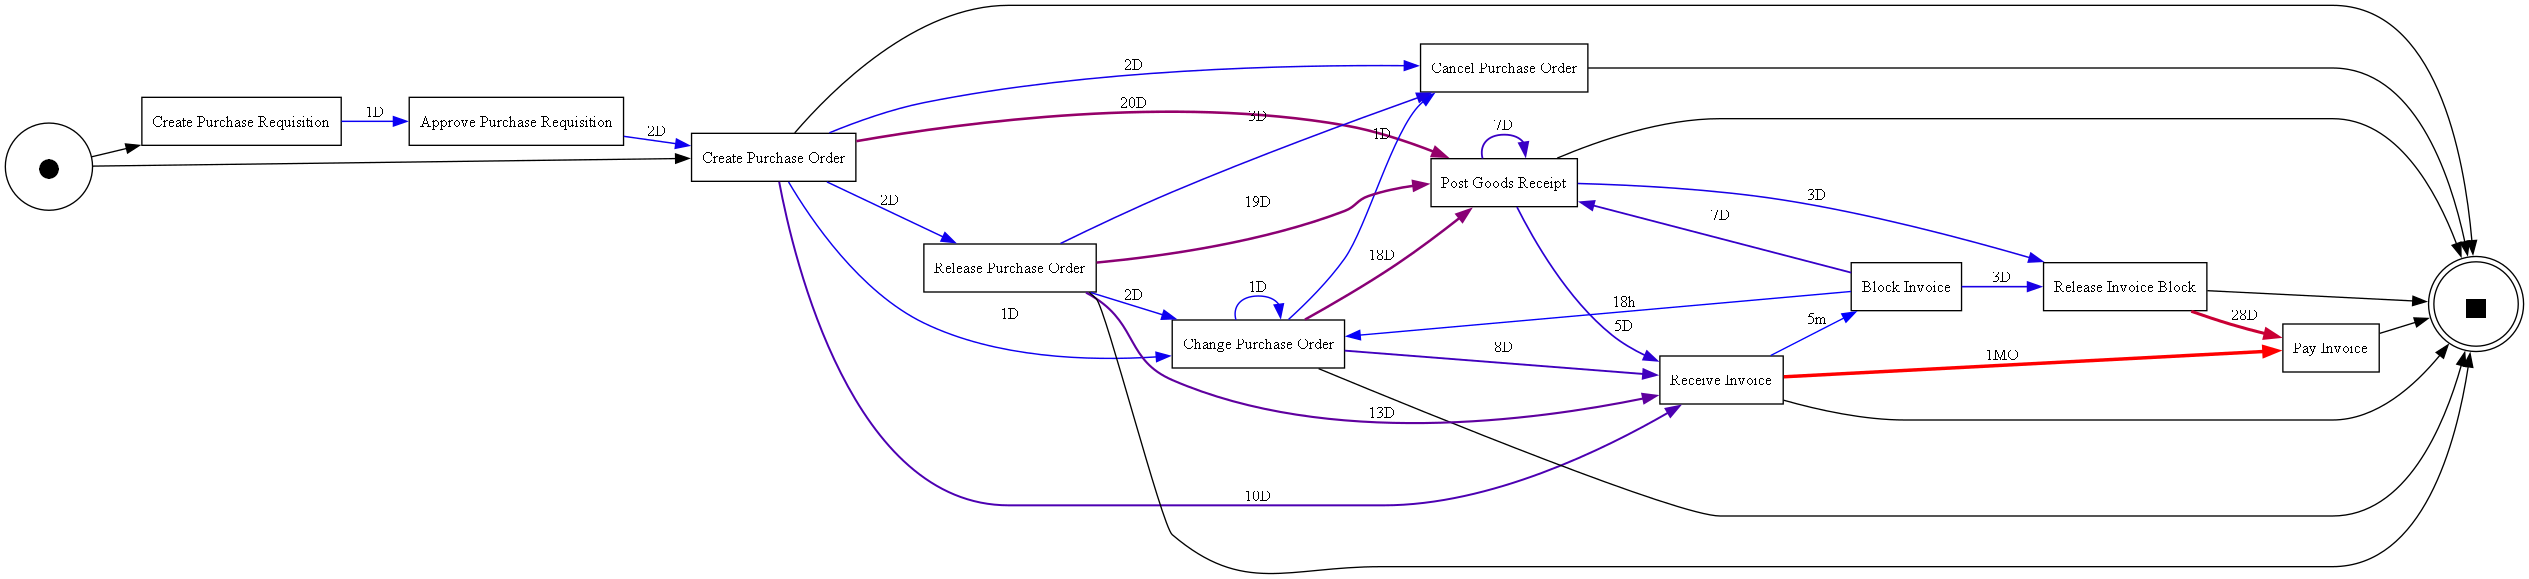

In [7]:
# Frequency map
dfg, start_acts, end_acts = pm4py.discover_dfg(event_log_df)
pm4py.view_dfg(dfg, start_acts, end_acts)

# Performance map (average time between steps)
perf_dfg, s, e = pm4py.discover_performance_dfg(event_log_df)
pm4py.view_performance_dfg(perf_dfg, s, e)

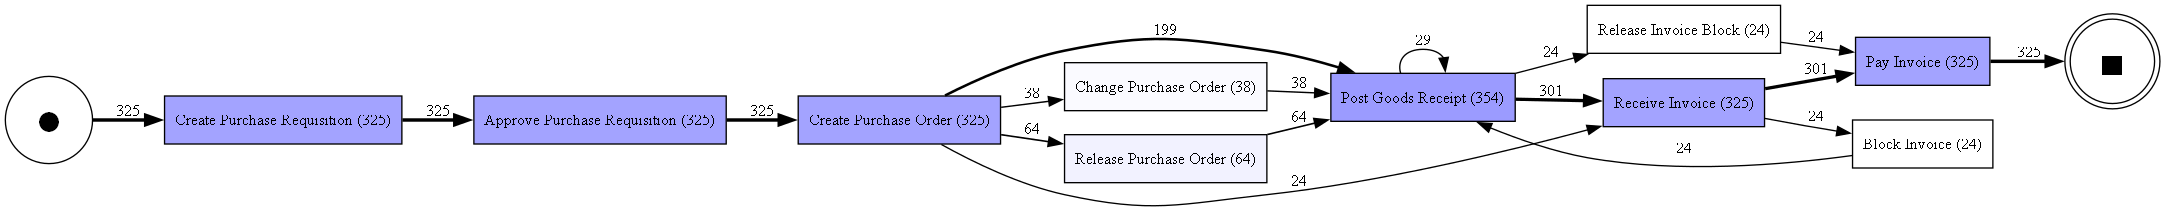

In [8]:
top_log = pm4py.filter_variants_top_k(event_log_df, 5)
dfg, s, e = pm4py.discover_dfg(top_log)
pm4py.view_dfg(dfg, s, e)

In [9]:
import pandas as pd

# Every activity function must return exactly these columns
EVENT_COLS = [
    "case_id", "activity", "timestamp", "resource",
    "source_table", "source_key",
    "vendor_id", "vendor_name", "total_value", "currency",
    "item_count", "plant_id",
]

def act_create_po(dfs):
    po   = dfs["EKKO_po_header"].copy()
    items = dfs["EKPO_po_items"]
    ven  = dfs["LFA1_vendors"][["vendor_id", "vendor_name"]]

    # extra attributes from other tables
    item_agg = (items.groupby("po_id")
                .agg(item_count=("po_item", "count"), plant_id=("plant_id", "first"))
                .reset_index())

    ev = (po.merge(ven, on="vendor_id", how="left")
            .merge(item_agg, on="po_id", how="left"))

    ev["case_id"]      = ev["po_id"].astype(str)
    ev["activity"]     = "Create Purchase Order"
    ev["timestamp"]    = pd.to_datetime(ev["created_at"])
    ev["resource"]     = ev["created_by"]
    ev["source_table"] = "EKKO_po_header"
    ev["source_key"]   = ev["po_id"].astype(str)

    return ev[EVENT_COLS]

In [10]:
activity_new = act_create_po(dfs)
print(activity_new.shape)          # expect (600, 12), one row per PO
print(activity_new.head())

(600, 12)
      case_id               activity           timestamp resource  \
0  4500000001  Create Purchase Order 2026-06-19 08:38:29    BUY03   
1  4500000002  Create Purchase Order 2026-03-19 08:34:49    BUY02   
2  4500000003  Create Purchase Order 2026-05-18 08:36:36    BUY01   
3  4500000004  Create Purchase Order 2026-05-08 08:25:32    BUY01   
4  4500000005  Create Purchase Order 2026-02-13 11:38:11    BUY03   

     source_table  source_key vendor_id           vendor_name total_value  \
0  EKKO_po_header  4500000001   V100018  Birla Cement Traders    25302.92   
1  EKKO_po_header  4500000002   V100021        Voltas Cooling   176710.79   
2  EKKO_po_header  4500000003   V100019        Finolex Cables      1562.2   
3  EKKO_po_header  4500000004   V100003      Mahindra Tooling   108522.92   
4  EKKO_po_header  4500000005   V100014  Jindal Steel Traders    37635.26   

  currency  item_count plant_id  
0      INR           2     3000  
1      INR           4     3000  
2      INR

In [11]:
def act_release_po(dfs):
    po = dfs["EKKO_po_header"].copy()
    po = po[po["released_at"].notna() & (po["released_at"].astype(str) != "")]   # only if it happened
    ven = dfs["LFA1_vendors"][["vendor_id", "vendor_name"]]
    ev = po.merge(ven, on="vendor_id", how="left")

    ev["case_id"]      = ev["po_id"].astype(str)
    ev["activity"]     = "Release Purchase Order"
    ev["timestamp"]    = pd.to_datetime(ev["released_at"])
    ev["resource"]     = ev["released_by"]
    ev["source_table"] = "EKKO_po_header"
    ev["source_key"]   = ev["po_id"].astype(str)
    ev["item_count"]   = None
    ev["plant_id"]     = None
    return ev[EVENT_COLS]

ACTIVITY_FUNCS = [act_create_po]          # add act_release_po, etc. here as you build them

def build_activity_new(dfs):
    parts = [f(dfs) for f in ACTIVITY_FUNCS]
    out = pd.concat(parts, ignore_index=True)
    return out.sort_values(["case_id", "timestamp"]).reset_index(drop=True)

activity_new = build_activity_new(dfs)

In [12]:
print(activity_new.shape)          # expect (600, 12), one row per PO

(600, 12)


In [13]:
def act_clear_invoice(dfs):
    pay = dfs["PAYMENTS"].copy()
    rseg = dfs["RSEG_invoice_items"].copy()
    po   = dfs["EKKO_po_header"][["po_id", "currency", "total_value"]]
    ven  = dfs["LFA1_vendors"][["vendor_id", "vendor_name"]]
    items = dfs["EKPO_po_items"]

    # invoice -> PO link, plus invoice line count
    inv_po = (rseg.groupby(["invoice_id", "po_id"])
                  .agg(item_count=("inv_item", "count"))
                  .reset_index())

    plant = (items.groupby("po_id")["plant_id"].first().reset_index())

    ev = (pay.merge(inv_po, on="invoice_id", how="inner")      # payment -> PO
             .merge(po, on="po_id", how="left", suffixes=("_pay", ""))
             .merge(ven, on="vendor_id", how="left")
             .merge(plant, on="po_id", how="left"))

    ev["case_id"]      = ev["po_id"].astype(str)
    ev["activity"]     = "Clear Invoice"
    ev["timestamp"]    = pd.to_datetime(ev["payment_ts"])
    ev["resource"]     = ev["paid_by"]
    ev["source_table"] = "PAYMENTS"
    ev["source_key"]   = ev["payment_doc_id"].astype(str)

    return ev[EVENT_COLS]

In [14]:
ACTIVITY_FUNCS = [act_create_po, act_clear_invoice]   # add act_release_po etc. here too
activity_new = build_activity_new(dfs)

print(activity_new["activity"].value_counts())

activity
Create Purchase Order    600
Clear Invoice            483
Name: count, dtype: int64


In [15]:
import pandas as pd
import pm4py

log = activity_new.copy()
log["case_id"] = log["case_id"].astype(str)
log["timestamp"] = pd.to_datetime(log["timestamp"])
log = log.sort_values(["case_id", "timestamp"])

log = pm4py.format_dataframe(
    log,
    case_id="case_id",
    activity_key="activity",
    timestamp_key="timestamp",
)

print(log["case:concept:name"].nunique(), "cases")
print(log["concept:name"].value_counts())

600 cases
concept:name
Create Purchase Order    600
Clear Invoice            483
Name: count, dtype: Int64


In [16]:
dfg, start_acts, end_acts = pm4py.discover_dfg(log)

print("Edges:", dfg)              # {('Create Purchase Order', 'Clear Invoice'): <count>}
print("Start:", start_acts)       # {'Create Purchase Order': 600}
print("End:", end_acts)           # {'Clear Invoice': <paid count>, 'Create Purchase Order': <unpaid count>}

Edges: {('Create Purchase Order', 'Clear Invoice'): 483}
Start: {'Create Purchase Order': 600}
End: {'Clear Invoice': 483, 'Create Purchase Order': 117}


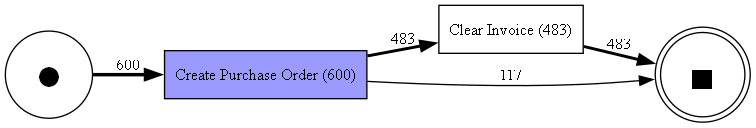

In [17]:
pm4py.view_dfg(dfg, start_acts, end_acts)

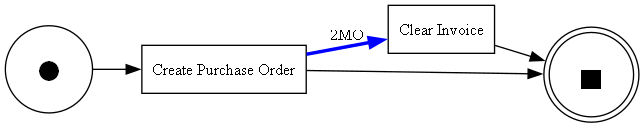

count    483.000000
mean      62.219462
std       17.704041
min       23.000000
25%       50.000000
50%       62.000000
75%       73.000000
max      112.000000
dtype: float64


In [18]:
perf_dfg, s, e = pm4py.discover_performance_dfg(log)
pm4py.view_performance_dfg(perf_dfg, s, e)

# the same number in plain days
import numpy as np
d = log.pivot_table(index="case:concept:name", columns="concept:name",
                    values="time:timestamp", aggfunc="min")
d = d.dropna(subset=["Clear Invoice"])
print((d["Clear Invoice"] - d["Create Purchase Order"]).dt.days.describe())

{('Create Purchase Order', 'Clear Invoice'): {'mean': np.float64(5403370.952380952), 'median': np.float64(5424847.0), 'max': np.float64(9701941.0), 'min': np.float64(1995366.0), 'sum': np.float64(2609828170.0), 'stdev': np.float64(1529191.866354941)}}


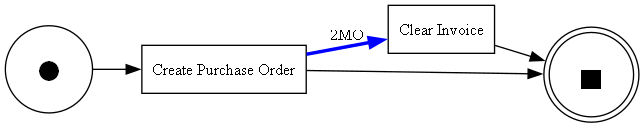

In [19]:
perf_dfg, s, e = pm4py.discover_performance_dfg(log)
print(perf_dfg)   # raw values are in SECONDS

pm4py.view_performance_dfg(perf_dfg, s, e, aggregation_measure="mean")   # or "median", "max", "min", "sum"

In [20]:
d = log.pivot_table(index="case:concept:name", columns="concept:name",
                    values="time:timestamp", aggfunc="min")
d = d.dropna(subset=["Clear Invoice"])

delta = d["Clear Invoice"] - d["Create Purchase Order"]
days = delta.dt.total_seconds() / 86400        # use total_seconds, not .dt.days, which drops the hours

summary = days.describe().round(2)
summary.index = [f"{i}" for i in summary.index]
print("Time from Create Purchase Order to Clear Invoice, in DAYS")
print(summary)

print("\nMean:   ", round(days.mean(), 1), "days =", round(days.mean() * 24), "hours")
print("Median: ", round(days.median(), 1), "days")
print("Min/Max:", round(days.min(), 1), "/", round(days.max(), 1), "days")

Time from Create Purchase Order to Clear Invoice, in DAYS
count    483.00
mean      62.54
std       17.70
min       23.09
25%       50.23
50%       62.79
75%       73.93
max      112.29
dtype: float64

Mean:    62.5 days = 1501 hours
Median:  62.8 days
Min/Max: 23.1 / 112.3 days


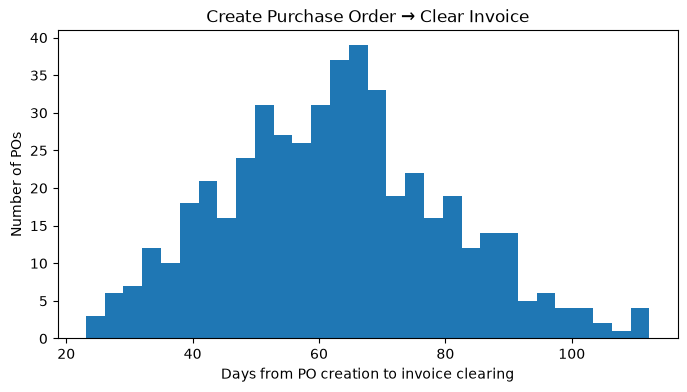

In [21]:
import matplotlib.pyplot as plt
days.plot(kind="hist", bins=30, figsize=(8, 4))
plt.xlabel("Days from PO creation to invoice clearing")
plt.ylabel("Number of POs")
plt.title("Create Purchase Order → Clear Invoice")
plt.show()

In [22]:
import base64, io, subprocess, webbrowser, os
import pandas as pd
import matplotlib.pyplot as plt
import pm4py
from pm4py.visualization.dfg import visualizer as dfg_vis

DOT = r"C:\Program Files\Graphviz\bin\dot.exe"   # change if Graphviz is elsewhere

# key name pm4py uses for the performance statistic (differs slightly by version)
try:
    from pm4py.visualization.dfg.variants.performance import Parameters as PerfParams
    AGG_KEY = PerfParams.AGGREGATION_MEASURE
except Exception:
    AGG_KEY = "aggregationMeasure"


def gviz_to_b64(gviz):
    """Render a graphviz object to PNG by calling dot.exe directly (no PATH needed)."""
    png = subprocess.run([DOT, "-Tpng"], input=gviz.source.encode("utf-8"),
                         capture_output=True, check=True).stdout
    return base64.b64encode(png).decode()


def fig_to_b64(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()


def img_tag(b64, alt=""):
    return f'<img alt="{alt}" src="data:image/png;base64,{b64}" style="max-width:100%;height:auto;">'


def edge_stat(v, stat="mean"):
    """Seconds for an edge, whether pm4py gave a number, a dict of stats, or nothing."""
    if v is None:
        return float("nan")
    if isinstance(v, dict):
        return v.get(stat, float("nan"))
    return v


def build_report(activity_new, log, path="p2p_process_report.html"):
    # ---------- numbers ----------
    n_cases  = log["case:concept:name"].nunique()
    n_events = len(log)
    t_min, t_max = log["time:timestamp"].min(), log["time:timestamp"].max()

    act_counts = (log["concept:name"].value_counts()
                  .rename_axis("Activity").reset_index(name="Events"))

    # ---------- DFGs ----------
    dfg, s, e = pm4py.discover_dfg(log)
    freq_b64 = gviz_to_b64(dfg_vis.apply(
        dfg, variant=dfg_vis.Variants.FREQUENCY,
        parameters={"start_activities": s, "end_activities": e}))

    perf_dfg, ps, pe = pm4py.discover_performance_dfg(log)
    perf_b64 = gviz_to_b64(dfg_vis.apply(
        perf_dfg, variant=dfg_vis.Variants.PERFORMANCE,
        parameters={"start_activities": ps, "end_activities": pe,
                    AGG_KEY: "mean"}))

    edges = pd.DataFrame([
        {"From": a, "To": b,
         "Frequency": dfg[(a, b)],
         "Mean (days)":   round(edge_stat(perf_dfg.get((a, b)), "mean")   / 86400, 2),
         "Median (days)": round(edge_stat(perf_dfg.get((a, b)), "median") / 86400, 2),
         "Max (days)":    round(edge_stat(perf_dfg.get((a, b)), "max")    / 86400, 2),
         "Mean (hours)":  round(edge_stat(perf_dfg.get((a, b)), "mean")   / 3600, 1)}
        for (a, b) in dfg])

    # ---------- case durations (first -> last event, in days) ----------
    g = log.groupby("case:concept:name")["time:timestamp"]
    dur = (g.max() - g.min()).dt.total_seconds() / 86400
    dur_stats = dur.describe().round(2).rename_axis("Statistic").reset_index(name="Days")

    fig, ax = plt.subplots(figsize=(8, 3.5))
    dur.plot(kind="hist", bins=30, ax=ax, color="#4c78a8")
    ax.set_xlabel("Case duration (days)")
    ax.set_ylabel("Number of POs")
    ax.set_title("Case duration: first event to last event")
    hist_b64 = fig_to_b64(fig)

    # ---------- variants ----------
    variants = pm4py.get_variants(log)
    var_df = pd.DataFrame(
        [{"Variant": " → ".join(k), "Cases": v} for k, v in variants.items()]
    ).sort_values("Cases", ascending=False).reset_index(drop=True)
    var_df["% of cases"] = (100 * var_df["Cases"] / var_df["Cases"].sum()).round(1)

    # ---------- resources ----------
    res_df = (activity_new.groupby(["activity", "resource"]).size()
              .reset_index(name="Events").sort_values("Events", ascending=False).head(15))

    sample = activity_new.head(25)

    tbl = lambda df: df.to_html(index=False, classes="t", border=0)

    html = f"""<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<title>P2P Process Mining Report</title>
<style>
 body{{font-family:Arial,Helvetica,sans-serif;margin:0;background:#f4f6f8;color:#1f2933}}
 header{{background:#1f3a5f;color:#fff;padding:24px 40px}}
 header h1{{margin:0 0 4px 0;font-size:24px}}
 main{{max-width:1200px;margin:0 auto;padding:24px 40px}}
 section{{background:#fff;border-radius:8px;padding:20px 24px;margin-bottom:24px;box-shadow:0 1px 3px rgba(0,0,0,.08)}}
 h2{{margin-top:0;font-size:18px;border-bottom:2px solid #e4e7eb;padding-bottom:8px}}
 .kpis{{display:flex;gap:16px;flex-wrap:wrap}}
 .kpi{{flex:1;min-width:160px;background:#eef3f9;border-radius:8px;padding:14px 18px}}
 .kpi b{{display:block;font-size:24px;color:#1f3a5f}}
 table.t{{border-collapse:collapse;width:100%;font-size:13px}}
 table.t th{{background:#1f3a5f;color:#fff;text-align:left;padding:6px 10px}}
 table.t td{{padding:6px 10px;border-bottom:1px solid #e4e7eb}}
 .scroll{{overflow-x:auto}}
 .note{{color:#52606d;font-size:12px}}
</style></head><body>
<header><h1>Procure-to-Pay Process Mining Report</h1>
<div>Event data: {t_min:%d %b %Y} to {t_max:%d %b %Y}</div></header>
<main>
<section><h2>Overview</h2><div class="kpis">
 <div class="kpi"><b>{n_cases:,}</b>Cases (purchase orders)</div>
 <div class="kpi"><b>{n_events:,}</b>Events</div>
 <div class="kpi"><b>{log['concept:name'].nunique()}</b>Activities</div>
 <div class="kpi"><b>{dur.median():.1f} days</b>Median case duration</div>
 <div class="kpi"><b>{len(variants)}</b>Process variants</div>
</div></section>

<section><h2>Activities</h2>{tbl(act_counts)}</section>

<section><h2>Process map: frequency (DFG)</h2>{img_tag(freq_b64,'Frequency DFG')}
<p class="note">Numbers on arrows show how many times each transition happened.</p></section>

<section><h2>Process map: performance (DFG)</h2>{img_tag(perf_b64,'Performance DFG')}
<p class="note">Arrow labels show the mean time between activities (D = days, h = hours, m = minutes).</p></section>

<section><h2>Transitions: frequency and timing</h2><div class="scroll">{tbl(edges)}</div></section>

<section><h2>Case duration (days)</h2>{img_tag(hist_b64,'Duration histogram')}
{tbl(dur_stats)}</section>

<section><h2>Process variants</h2><div class="scroll">{tbl(var_df.head(15))}</div>
<p class="note">Top 15 of {len(variants)} variants.</p></section>

<section><h2>Top resources by activity</h2>{tbl(res_df)}</section>

<section><h2>Sample of activity_new</h2><div class="scroll">{tbl(sample)}</div></section>
</main></body></html>"""

    with open(path, "w", encoding="utf-8") as f:
        f.write(html)
    full = os.path.abspath(path)
    print("Saved:", full)
    webbrowser.open("file:///" + full.replace("\\", "/"))
    return full


build_report(activity_new, log)

Saved: c:\Users\Hitesh Chaudhary\OneDrive\Desktop\pm4pytest\p2p_process_report.html


'c:\\Users\\Hitesh Chaudhary\\OneDrive\\Desktop\\pm4pytest\\p2p_process_report.html'

In [24]:
import base64, io, subprocess, webbrowser, os
import pandas as pd
import matplotlib.pyplot as plt
import pm4py
from pm4py.visualization.dfg import visualizer as dfg_vis

DOT = r"C:\Program Files\Graphviz\bin\dot.exe"   # change if Graphviz is elsewhere

# key name pm4py uses for the performance statistic (differs slightly by version)
try:
    from pm4py.visualization.dfg.variants.performance import Parameters as PerfParams
    AGG_KEY = PerfParams.AGGREGATION_MEASURE
except Exception:
    AGG_KEY = "aggregationMeasure"


def gviz_to_b64(gviz):
    """Render a graphviz object to PNG by calling dot.exe directly (no PATH needed)."""
    png = subprocess.run([DOT, "-Tpng"], input=gviz.source.encode("utf-8"),
                         capture_output=True, check=True).stdout
    return base64.b64encode(png).decode()


def fig_to_b64(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()


def img_tag(b64, alt=""):
    return f'<img alt="{alt}" src="data:image/png;base64,{b64}" style="max-width:100%;height:auto;">'


def edge_stat(v, stat="mean"):
    """Seconds for an edge, whether pm4py gave a number, a dict of stats, or nothing."""
    if v is None:
        return float("nan")
    if isinstance(v, dict):
        return v.get(stat, float("nan"))
    return v


def prepare_log(event_log_df):
    """Return event_log_df in pm4py format (safe to call on raw or already formatted data)."""
    df = event_log_df.copy()
    if "case:concept:name" not in df.columns:
        df["case_id"] = df["case_id"].astype(str)
        df["timestamp"] = pd.to_datetime(df["timestamp"])
        df = pm4py.format_dataframe(df, case_id="case_id",
                                    activity_key="activity",
                                    timestamp_key="timestamp")
    df["case:concept:name"] = df["case:concept:name"].astype(str)
    df["time:timestamp"] = pd.to_datetime(df["time:timestamp"])
    return df.sort_values(["case:concept:name", "time:timestamp"]).reset_index(drop=True)


def build_report(event_log_df, path="p2p_process_report.html"):
    log = prepare_log(event_log_df)

    # ---------- numbers ----------
    n_cases  = log["case:concept:name"].nunique()
    n_events = len(log)
    t_min, t_max = log["time:timestamp"].min(), log["time:timestamp"].max()

    act_counts = (log["concept:name"].value_counts()
                  .rename_axis("Activity").reset_index(name="Events"))

    # ---------- DFGs ----------
    dfg, s, e = pm4py.discover_dfg(log)
    freq_b64 = gviz_to_b64(dfg_vis.apply(
        dfg, variant=dfg_vis.Variants.FREQUENCY,
        parameters={"start_activities": s, "end_activities": e}))

    perf_dfg, ps, pe = pm4py.discover_performance_dfg(log)
    perf_b64 = gviz_to_b64(dfg_vis.apply(
        perf_dfg, variant=dfg_vis.Variants.PERFORMANCE,
        parameters={"start_activities": ps, "end_activities": pe,
                    AGG_KEY: "mean"}))

    edges = pd.DataFrame([
        {"From": a, "To": b,
         "Frequency": dfg[(a, b)],
         "Mean (days)":   round(edge_stat(perf_dfg.get((a, b)), "mean")   / 86400, 2),
         "Median (days)": round(edge_stat(perf_dfg.get((a, b)), "median") / 86400, 2),
         "Max (days)":    round(edge_stat(perf_dfg.get((a, b)), "max")    / 86400, 2),
         "Mean (hours)":  round(edge_stat(perf_dfg.get((a, b)), "mean")   / 3600, 1)}
        for (a, b) in dfg]).sort_values("Frequency", ascending=False)

    # ---------- case durations (first -> last event, in days) ----------
    g = log.groupby("case:concept:name")["time:timestamp"]
    dur = (g.max() - g.min()).dt.total_seconds() / 86400
    dur_stats = dur.describe().round(2).rename_axis("Statistic").reset_index(name="Days")

    fig, ax = plt.subplots(figsize=(8, 3.5))
    dur.plot(kind="hist", bins=30, ax=ax, color="#4c78a8")
    ax.set_xlabel("Case duration (days)")
    ax.set_ylabel("Number of POs")
    ax.set_title("Case duration: first event to last event")
    hist_b64 = fig_to_b64(fig)

    # ---------- variants ----------
    variants = pm4py.get_variants(log)
    var_df = pd.DataFrame(
        [{"Variant": " → ".join(k), "Cases": v} for k, v in variants.items()]
    ).sort_values("Cases", ascending=False).reset_index(drop=True)
    var_df["% of cases"] = (100 * var_df["Cases"] / var_df["Cases"].sum()).round(1)

    # ---------- resources ----------
    res_col = "resource" if "resource" in log.columns else (
              "org:resource" if "org:resource" in log.columns else None)
    if res_col:
        res_df = (log.groupby(["concept:name", res_col]).size()
                  .reset_index(name="Events")
                  .rename(columns={"concept:name": "Activity", res_col: "Resource"})
                  .sort_values("Events", ascending=False).head(15))
    else:
        res_df = pd.DataFrame({"Info": ["No resource column in event_log_df"]})

    # ---------- sample rows ----------
    wanted = ["case:concept:name", "concept:name", "time:timestamp", res_col,
              "source_table", "source_key", "vendor_id", "total_value"]
    sample = log[[c for c in wanted if c and c in log.columns]].head(25)

    tbl = lambda df: df.to_html(index=False, classes="t", border=0)

    html = f"""<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<title>P2P Process Mining Report</title>
<style>
 body{{font-family:Arial,Helvetica,sans-serif;margin:0;background:#f4f6f8;color:#1f2933}}
 header{{background:#1f3a5f;color:#fff;padding:24px 40px}}
 header h1{{margin:0 0 4px 0;font-size:24px}}
 main{{max-width:1200px;margin:0 auto;padding:24px 40px}}
 section{{background:#fff;border-radius:8px;padding:20px 24px;margin-bottom:24px;box-shadow:0 1px 3px rgba(0,0,0,.08)}}
 h2{{margin-top:0;font-size:18px;border-bottom:2px solid #e4e7eb;padding-bottom:8px}}
 .kpis{{display:flex;gap:16px;flex-wrap:wrap}}
 .kpi{{flex:1;min-width:160px;background:#eef3f9;border-radius:8px;padding:14px 18px}}
 .kpi b{{display:block;font-size:24px;color:#1f3a5f}}
 table.t{{border-collapse:collapse;width:100%;font-size:13px}}
 table.t th{{background:#1f3a5f;color:#fff;text-align:left;padding:6px 10px}}
 table.t td{{padding:6px 10px;border-bottom:1px solid #e4e7eb}}
 .scroll{{overflow-x:auto}}
 .note{{color:#52606d;font-size:12px}}
</style></head><body>
<header><h1>Procure-to-Pay Process Mining Report</h1>
<div>Event data: {t_min:%d %b %Y} to {t_max:%d %b %Y}</div></header>
<main>
<section><h2>Overview</h2><div class="kpis">
 <div class="kpi"><b>{n_cases:,}</b>Cases (purchase orders)</div>
 <div class="kpi"><b>{n_events:,}</b>Events</div>
 <div class="kpi"><b>{log['concept:name'].nunique()}</b>Activities</div>
 <div class="kpi"><b>{dur.median():.1f} days</b>Median case duration</div>
 <div class="kpi"><b>{len(variants)}</b>Process variants</div>
</div></section>

<section><h2>Activities</h2>{tbl(act_counts)}</section>

<section><h2>Process map: frequency (DFG)</h2>{img_tag(freq_b64,'Frequency DFG')}
<p class="note">Numbers on arrows show how many times each transition happened.</p></section>

<section><h2>Process map: performance (DFG)</h2>{img_tag(perf_b64,'Performance DFG')}
<p class="note">Arrow labels show the mean time between activities (D = days, h = hours, m = minutes).</p></section>

<section><h2>Transitions: frequency and timing</h2><div class="scroll">{tbl(edges)}</div></section>

<section><h2>Case duration (days)</h2>{img_tag(hist_b64,'Duration histogram')}
{tbl(dur_stats)}</section>

<section><h2>Process variants</h2><div class="scroll">{tbl(var_df.head(15))}</div>
<p class="note">Top 15 of {len(variants)} variants.</p></section>

<section><h2>Top resources by activity</h2>{tbl(res_df)}</section>

<section><h2>Sample of event_log_df</h2><div class="scroll">{tbl(sample)}</div></section>
</main></body></html>"""

    with open(path, "w", encoding="utf-8") as f:
        f.write(html)
    full = os.path.abspath(path)
    print("Saved:", full)
    webbrowser.open("file:///" + full.replace("\\", "/"))
    return full


build_report(event_log_df)

Saved: c:\Users\Hitesh Chaudhary\OneDrive\Desktop\pm4pytest\p2p_process_report.html


'c:\\Users\\Hitesh Chaudhary\\OneDrive\\Desktop\\pm4pytest\\p2p_process_report.html'